# 沪深300两批等份额 T+1 策略

仅读取本 Notebook 所在文件夹中的 `000300.SH-*.xlsx`。回测 2005-01-01 至 2025-12-31，每个自然年独立起算净值 1.00；绘制年度图和 2005–2009、2010–2019、2020–2025 三个区间的累计净值图。

**策略交易规则：** 每年测试期前一个交易日收盘时，假定已持有价值 1.00 的沪深300旧份额，并把份数等分为两批。先卖出其中一批；次日早盘买回**完全相同的份数**，收盘只卖出另一批旧份额。之后每天早盘买回一批固定份数，收盘卖出隔夜持有的旧份额；当日买入的份额留至下一交易日，从而符合 T+1。每年重新确定两批份额的数量，当年内份数保持不变。初始旧份额是在测试期前已持有的资产，不计入本回测的买入交易。

交易费用按每笔买入和卖出成交金额的 0.015% 收取；期初前一交易日收盘卖出一批的费用计入当年首日收益率。买回相同份数可能出现现金缺口，现金账户允许为负，按零利息短期融资处理；`financing_gap_open` 记录资金缺口。年末不额外强制清仓。

主指标和图表使用真实跟踪份额与现金的 `strategy_return` / `strategy_nav`。`mean_return_formula` 仅作数学对照：它等于开盘至收盘收益率与昨收至今收收益率的平均值，**不保证等于固定份额策略的实际收益**。基准从相同前一交易日收盘点位持有 100% 沪深300，不再交易。

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA_DIR = Path.cwd()
SOURCE_CODE = '000300.SH'
START_DATE = pd.Timestamp('2005-01-01')
END_DATE = pd.Timestamp('2025-12-31')
TRADE_FEE_RATE = 0.00015
TRADING_DAYS_PER_YEAR = 252
RISK_FREE_ANNUAL = 0.0
TEST_PERIODS = [(f'{year}-01-01', f'{year}-12-31') for year in range(2005, 2026)]

matches = sorted(DATA_DIR.glob(f'{SOURCE_CODE}-*.xlsx'))
if len(matches) != 1:
    raise FileNotFoundError(f'{SOURCE_CODE}: 预期恰好 1 个 Excel 文件，实际找到 {len(matches)} 个')

history = pd.read_excel(matches[0], sheet_name='Sheet',
                        usecols=['交易日期', '开盘点位', '收盘价'], dtype=str)
history = history.rename(columns={'交易日期': 'date',
                                  '开盘点位': 'open', '收盘价': 'close'})
history['date'] = pd.to_datetime(history['date'], errors='raise').dt.normalize()
for column in ('open', 'close'):
    history[column] = pd.to_numeric(
        history[column].str.replace(',', '', regex=False).str.strip(), errors='raise')
history = history.sort_values('date').reset_index(drop=True)
prices = history.loc[history['date'].between(START_DATE, END_DATE)].copy()
if prices.empty or prices[['date', 'open', 'close']].isna().any().any():
    raise ValueError('指定范围内的日期或点位存在缺失')
if prices['date'].duplicated().any() or (prices[['open', 'close']] <= 0).any().any():
    raise ValueError('交易日期重复或指数点位非正')

print(f'来源：{matches[0].name}；交易日：{len(prices):,}；'
      f'{prices.date.min().date()} 至 {prices.date.max().date()}')
prices.head()

来源：000300.SH-行情统计-20261025.xlsx；交易日：5,101；2005-01-04 至 2025-12-31


,date,open,close
1,2005-01-04,994.77,982.79
2,2005-01-05,981.58,992.56
3,2005-01-06,993.33,983.17
4,2005-01-07,983.05,983.96
5,2005-01-10,983.76,993.88


## 逐年回测

`lot_shares` 是每年固定的一批份数。每天早盘买回一批，收盘只卖出前一日已持有的一批；现金账户记录买卖差额及费用。`mean_return_formula` 用标准百分比收益率计算，只用于核对两批等份额交易与平均收益公式的差别。

In [14]:
def backtest_one_year(start, end):
    year = int(start[:4])
    year_prices = prices.loc[prices['date'].between(start, end)]
    if year_prices.empty:
        raise ValueError(f'{year}: 没有交易日')

    first_date = year_prices['date'].iloc[0]
    prior = history.loc[history['date'] < first_date]
    if prior.empty:
        raise ValueError(f'{year}: 缺少测试期前一个交易日收盘点位')
    reference_close = float(prior.iloc[-1]['close'])
    previous_close = reference_close

    # 两批固定份数的可执行模拟，从前一日已持有的 100% 旧份额开始。
    lot_shares = 0.5 / reference_close
    overnight_shares = lot_shares
    prior_close_sale_notional = 0.5
    prior_close_sale_fee = TRADE_FEE_RATE * prior_close_sale_notional
    cash = prior_close_sale_notional - prior_close_sale_fee
    benchmark_shares = 1.0 / reference_close

    previous_formula_nav = 1.0
    previous_execution_nav = 1.0
    previous_benchmark_nav = 1.0
    records = []

    for day_number, row in enumerate(year_prices.itertuples(index=False)):
        open_price, close_price = float(row.open), float(row.close)

        # 平均收益公式仅作对照；实际策略按两批等份额及现金流水计算。
        intraday_return = close_price / open_price - 1.0
        close_to_close_return = close_price / previous_close - 1.0
        mean_return_formula = (intraday_return + close_to_close_return) / 2.0

        # 对照公式的名义费用，仅用于显示理论公式净值，不作为主策略。
        formula_buy_notional = 0.5 * previous_formula_nav
        formula_sell_notional_close = 0.5 * previous_formula_nav * close_price / previous_close
        formula_prior_sale_notional = 0.5 * previous_formula_nav if day_number == 0 else 0.0
        formula_transaction_cost = TRADE_FEE_RATE * (
            formula_buy_notional + formula_sell_notional_close + formula_prior_sale_notional
        )
        fee_return = formula_transaction_cost / previous_formula_nav
        formula_return = mean_return_formula - fee_return
        formula_nav = previous_formula_nav * (1.0 + formula_return)

        # 固定份数 T+1 执行模拟：早盘买回一批，收盘只卖旧的一批。
        new_shares = lot_shares
        buy_notional_open = new_shares * open_price
        buy_fee = TRADE_FEE_RATE * buy_notional_open
        cash_after_open = cash - buy_notional_open - buy_fee
        financing_gap_open = max(0.0, -cash_after_open)
        shares_sold_close = overnight_shares
        sell_notional_close = shares_sold_close * close_price
        sell_fee = TRADE_FEE_RATE * sell_notional_close
        cash = cash_after_open + sell_notional_close - sell_fee
        execution_nav = new_shares * close_price + cash
        execution_transaction_cost = (buy_fee + sell_fee +
                                      (prior_close_sale_fee if day_number == 0 else 0.0))
        execution_return = execution_nav / previous_execution_nav - 1.0

        benchmark_nav = benchmark_shares * close_price
        benchmark_return = benchmark_nav / previous_benchmark_nav - 1.0
        records.append({
            'date': row.date, 'year': year,
            'open': open_price, 'close': close_price, 'previous_close': previous_close,
            'intraday_return': intraday_return,
            'close_to_close_return': close_to_close_return,
            'mean_return_formula': mean_return_formula,
            'formula_buy_notional': formula_buy_notional,
            'formula_sell_notional_close': formula_sell_notional_close,
            'formula_prior_sale_notional': formula_prior_sale_notional,
            'formula_transaction_cost': formula_transaction_cost,
            'fee_return': fee_return,
            'formula_return': formula_return, 'formula_nav': formula_nav,
            'strategy_return': execution_return, 'strategy_nav': execution_nav,
            'benchmark_return': benchmark_return, 'benchmark_nav': benchmark_nav,
            'lot_shares': lot_shares,
            'old_shares_sold_close': shares_sold_close,
            'new_shares_held_overnight': new_shares,
            'prior_close_sale_notional': prior_close_sale_notional if day_number == 0 else 0.0,
            'buy_notional_open': buy_notional_open,
            'sell_notional_close': sell_notional_close,
            'cash_after_open': cash_after_open,
            'financing_gap_open': financing_gap_open,
            'cash_after_close': cash,
            'transaction_cost': execution_transaction_cost,
            'execution_transaction_cost': execution_transaction_cost,
            'execution_return': execution_return,
            'execution_nav': execution_nav,
        })

        overnight_shares = new_shares
        previous_close = close_price
        previous_formula_nav = formula_nav
        previous_execution_nav = execution_nav
        previous_benchmark_nav = benchmark_nav

    return pd.DataFrame.from_records(records)


backtest_df = pd.concat(
    [backtest_one_year(start, end) for start, end in TEST_PERIODS],
    ignore_index=True,
)
backtest_df[['date', 'intraday_return', 'close_to_close_return',
             'mean_return_formula', 'fee_return', 'formula_return',
             'strategy_return', 'benchmark_return']].head()

,date,intraday_return,close_to_close_return,mean_return_formula,fee_return,formula_return,strategy_return,benchmark_return
0,2005-01-04,-0.012043,-0.017210,-0.014626,0.000224,-0.014850,-0.014818,-0.017210
1,2005-01-05,0.011186,0.009941,0.010564,0.000151,0.010413,0.010381,0.009941
2,2005-01-06,-0.010228,-0.009460,-0.009844,0.000149,-0.009994,-0.009969,-0.009460
3,2005-01-07,0.000926,0.000804,0.000865,0.000150,0.000715,0.000713,0.000804
4,2005-01-10,0.010287,0.010082,0.010184,0.000151,0.010034,0.010010,0.010082


In [15]:
# 核对等份额与 T+1：当日卖出的旧份额等于上一日早盘买入的份额。
for _, year_data in backtest_df.groupby('year', sort=True):
    if len(year_data) > 1:
        np.testing.assert_allclose(
            year_data['old_shares_sold_close'].iloc[1:].to_numpy(),
            year_data['new_shares_held_overnight'].iloc[:-1].to_numpy(),
            rtol=0, atol=1e-12,
        )
np.testing.assert_allclose(backtest_df['new_shares_held_overnight'],
                           backtest_df['lot_shares'], rtol=0, atol=1e-12)
np.testing.assert_allclose(backtest_df['old_shares_sold_close'],
                           backtest_df['lot_shares'], rtol=0, atol=1e-12)
np.testing.assert_allclose(
    backtest_df['mean_return_formula'],
    (backtest_df['intraday_return'] + backtest_df['close_to_close_return']) / 2,
    rtol=0, atol=1e-12,
)
np.testing.assert_allclose(backtest_df['strategy_nav'], backtest_df['execution_nav'],
                           rtol=0, atol=1e-12)
np.testing.assert_allclose(backtest_df['strategy_return'], backtest_df['execution_return'],
                           rtol=0, atol=1e-12)

backtest_df['gross_strategy_return'] = (
    backtest_df['strategy_return'] +
    backtest_df['execution_transaction_cost'] /
    backtest_df.groupby('year')['strategy_nav'].shift(1).fillna(1.0)
)
backtest_df['gross_minus_mean_return'] = (
    backtest_df['gross_strategy_return'] - backtest_df['mean_return_formula']
)
audit_summary = backtest_df.groupby('year').agg(
    fixed_lots_final_nav=('strategy_nav', 'last'),
    benchmark_final_nav=('benchmark_nav', 'last'),
    max_daily_gross_gap=('gross_minus_mean_return',
                         lambda x: float(x.abs().max())),
    financing_days=('financing_gap_open', lambda x: int((x > 0).sum())),
    max_financing_gap=('financing_gap_open', 'max'),
)
audit_summary.round(4)

,fixed_lots_final_nav,benchmark_final_nav,max_daily_gross_gap,financing_days,max_financing_gap
year,,,,,
2005,0.9279,0.9235,0.0011,25,0.0042
2006,2.1629,2.2102,0.0027,241,0.0710
2007,2.5417,2.6155,0.0020,219,0.1463
2008,0.4680,0.3405,0.0181,57,0.0232
2009,1.9502,1.9671,0.0021,72,0.0270
2010,0.9222,0.8749,0.0030,43,0.0178
2011,0.8393,0.7499,0.0035,8,0.0045
2012,1.1383,1.0755,0.0030,44,0.0059
2013,0.9622,0.9235,0.0028,35,0.0086


## 年度指标

年度回报 = 年末净值 − 1；年化波动 = 日收益率样本标准差 × √252；最大回撤 = 相对历史最高净值（含初始 1.00）的最大跌幅，报告正数；夏普比率按年化无风险利率 0% 计算；卡玛比率 = 年化收益率 ÷ 最大回撤，其中年化收益率 = 年末净值^(252 / 当年交易日数) − 1。波动或回撤为零时，比率记为缺失值。百分比指标以百分数输出。

In [16]:
risk_free_daily = (1.0 + RISK_FREE_ANNUAL) ** (1.0 / TRADING_DAYS_PER_YEAR) - 1.0


def annual_metrics(yearly, portfolio, nav_column, return_column):
    nav = yearly[nav_column].to_numpy(dtype=float)
    daily_returns = yearly[return_column].to_numpy(dtype=float)
    volatility_daily = float(np.std(daily_returns, ddof=1))
    running_peak = np.maximum.accumulate(np.r_[1.0, nav])[1:]
    max_drawdown = float(np.max(1.0 - nav / running_peak))
    annualized_return = float(nav[-1] ** (TRADING_DAYS_PER_YEAR / len(nav)) - 1.0)
    return {
        'year': int(yearly['year'].iloc[0]), 'portfolio': portfolio,
        'annual_return_pct': 100.0 * (float(nav[-1]) - 1.0),
        'annualized_volatility_pct': 100.0 * volatility_daily * np.sqrt(TRADING_DAYS_PER_YEAR),
        'max_drawdown_pct': 100.0 * max_drawdown,
        'sharpe_ratio': ((float(np.mean(daily_returns)) - risk_free_daily)
                         / volatility_daily * np.sqrt(TRADING_DAYS_PER_YEAR)
                         if volatility_daily > 0 else np.nan),
        'calmar_ratio': annualized_return / max_drawdown if max_drawdown > 0 else np.nan,
    }


metric_records = []
for _, yearly in backtest_df.groupby('year', sort=True):
    metric_records.append(annual_metrics(yearly, 'Fixed-share T+1',
                                         'strategy_nav', 'strategy_return'))
    metric_records.append(annual_metrics(yearly, 'CSI 300 buy and hold',
                                         'benchmark_nav', 'benchmark_return'))
annual_metrics_df = pd.DataFrame(metric_records).set_index(['year', 'portfolio'])
annual_metrics_df.round(4)

annual_return_pct  annualized_volatility_pct  \
year portfolio                                                            
2005 Fixed-share T+1                 -7.2125                    20.5341   
     CSI 300 buy and hold            -7.6550                    21.3277   
2006 Fixed-share T+1                116.2862                    22.4019   
     CSI 300 buy and hold           121.0244                    22.2871   
2007 Fixed-share T+1                154.1727                    35.6491   
     CSI 300 buy and hold           161.5458                    36.8107   
2008 Fixed-share T+1                -53.2024                    40.0758   
     CSI 300 buy and hold           -65.9493                    48.4516   
2009 Fixed-share T+1                 95.0207                    30.8631   
     CSI 300 buy and hold            96.7124                    32.6617   
2010 Fixed-share T+1                 -7.7834                    23.0115   
     CSI 300 buy and hold           -12.5129                    25.1363   
2011 Fixed-share T+1                -16.0739                    18.5793   
     CSI 300 buy and hold           -25.0145                    20.6635   
2012 Fixed-share T+1                 13.8270                    19.2088   
     CSI 300 buy and hold             7.5545                    20.4372   
2013 Fixed-share T+1                 -3.7800                    20.2843   
     CSI 300 buy and hold            -7.6466                    22.2203   
2014 Fixed-share T+1                 48.7433                    18.2751   
     CSI 300 buy and hold            51.6594                    19.2548   
2015 Fixed-share T+1                 18.4589                    35.5842   
     CSI 300 buy and hold             5.5831                    39.4256   
2016 Fixed-share T+1                 -2.5745                    20.1945   
     CSI 300 buy and hold           -11.2817                    22.2239   
2017 Fixed-share T+1                 27.5851                     9.5088   
     CSI 300 buy and hold            21.7750                    10.1465   
2018 Fixed-share T+1                -16.2290                    18.0252   
     CSI 300 buy and hold           -25.3098                    21.4243   
2019 Fixed-share T+1                 26.9552                    18.0504   
     CSI 300 buy and hold            36.0696                    19.8537   
2020 Fixed-share T+1                 26.6879                    18.5540   
     CSI 300 buy and hold            27.2107                    22.7709   
2021 Fixed-share T+1                 -1.6825                    17.5604   
     CSI 300 buy and hold            -5.1987                    18.5862   
2022 Fixed-share T+1                -15.4668                    17.6653   
     CSI 300 buy and hold           -21.6328                    20.4055   
2023 Fixed-share T+1                -15.4564                    12.9727   
     CSI 300 buy and hold           -11.3782                    13.5011   
2024 Fixed-share T+1                 14.5503                    18.3527   
     CSI 300 buy and hold            14.6833                    21.3864   
2025 Fixed-share T+1                 18.5793                    13.6341   
     CSI 300 buy and hold            17.6632                    15.2645   

                           max_drawdown_pct  sharpe_ratio  calmar_ratio  
year portfolio                                                           
2005 Fixed-share T+1                20.6494       -0.2783       -0.3632  
     CSI 300 buy and hold           22.0174       -0.2837       -0.3615  
2006 Fixed-share T+1                13.2621        3.7184        9.3528  
     CSI 300 buy and hold           13.8158        3.8383        9.3496  
2007 Fixed-share T+1                18.9339        2.9096        8.6702  
     CSI 300 buy and hold           20.9020        2.9105        8.2359  
2008 Fixed-share T+1                60.1767       -1.7379       -0.8984  
     CSI 300 buy and hold           71.6010       -2.0315   

## 每年的净值对照图（两批等份额 T+1 策略）

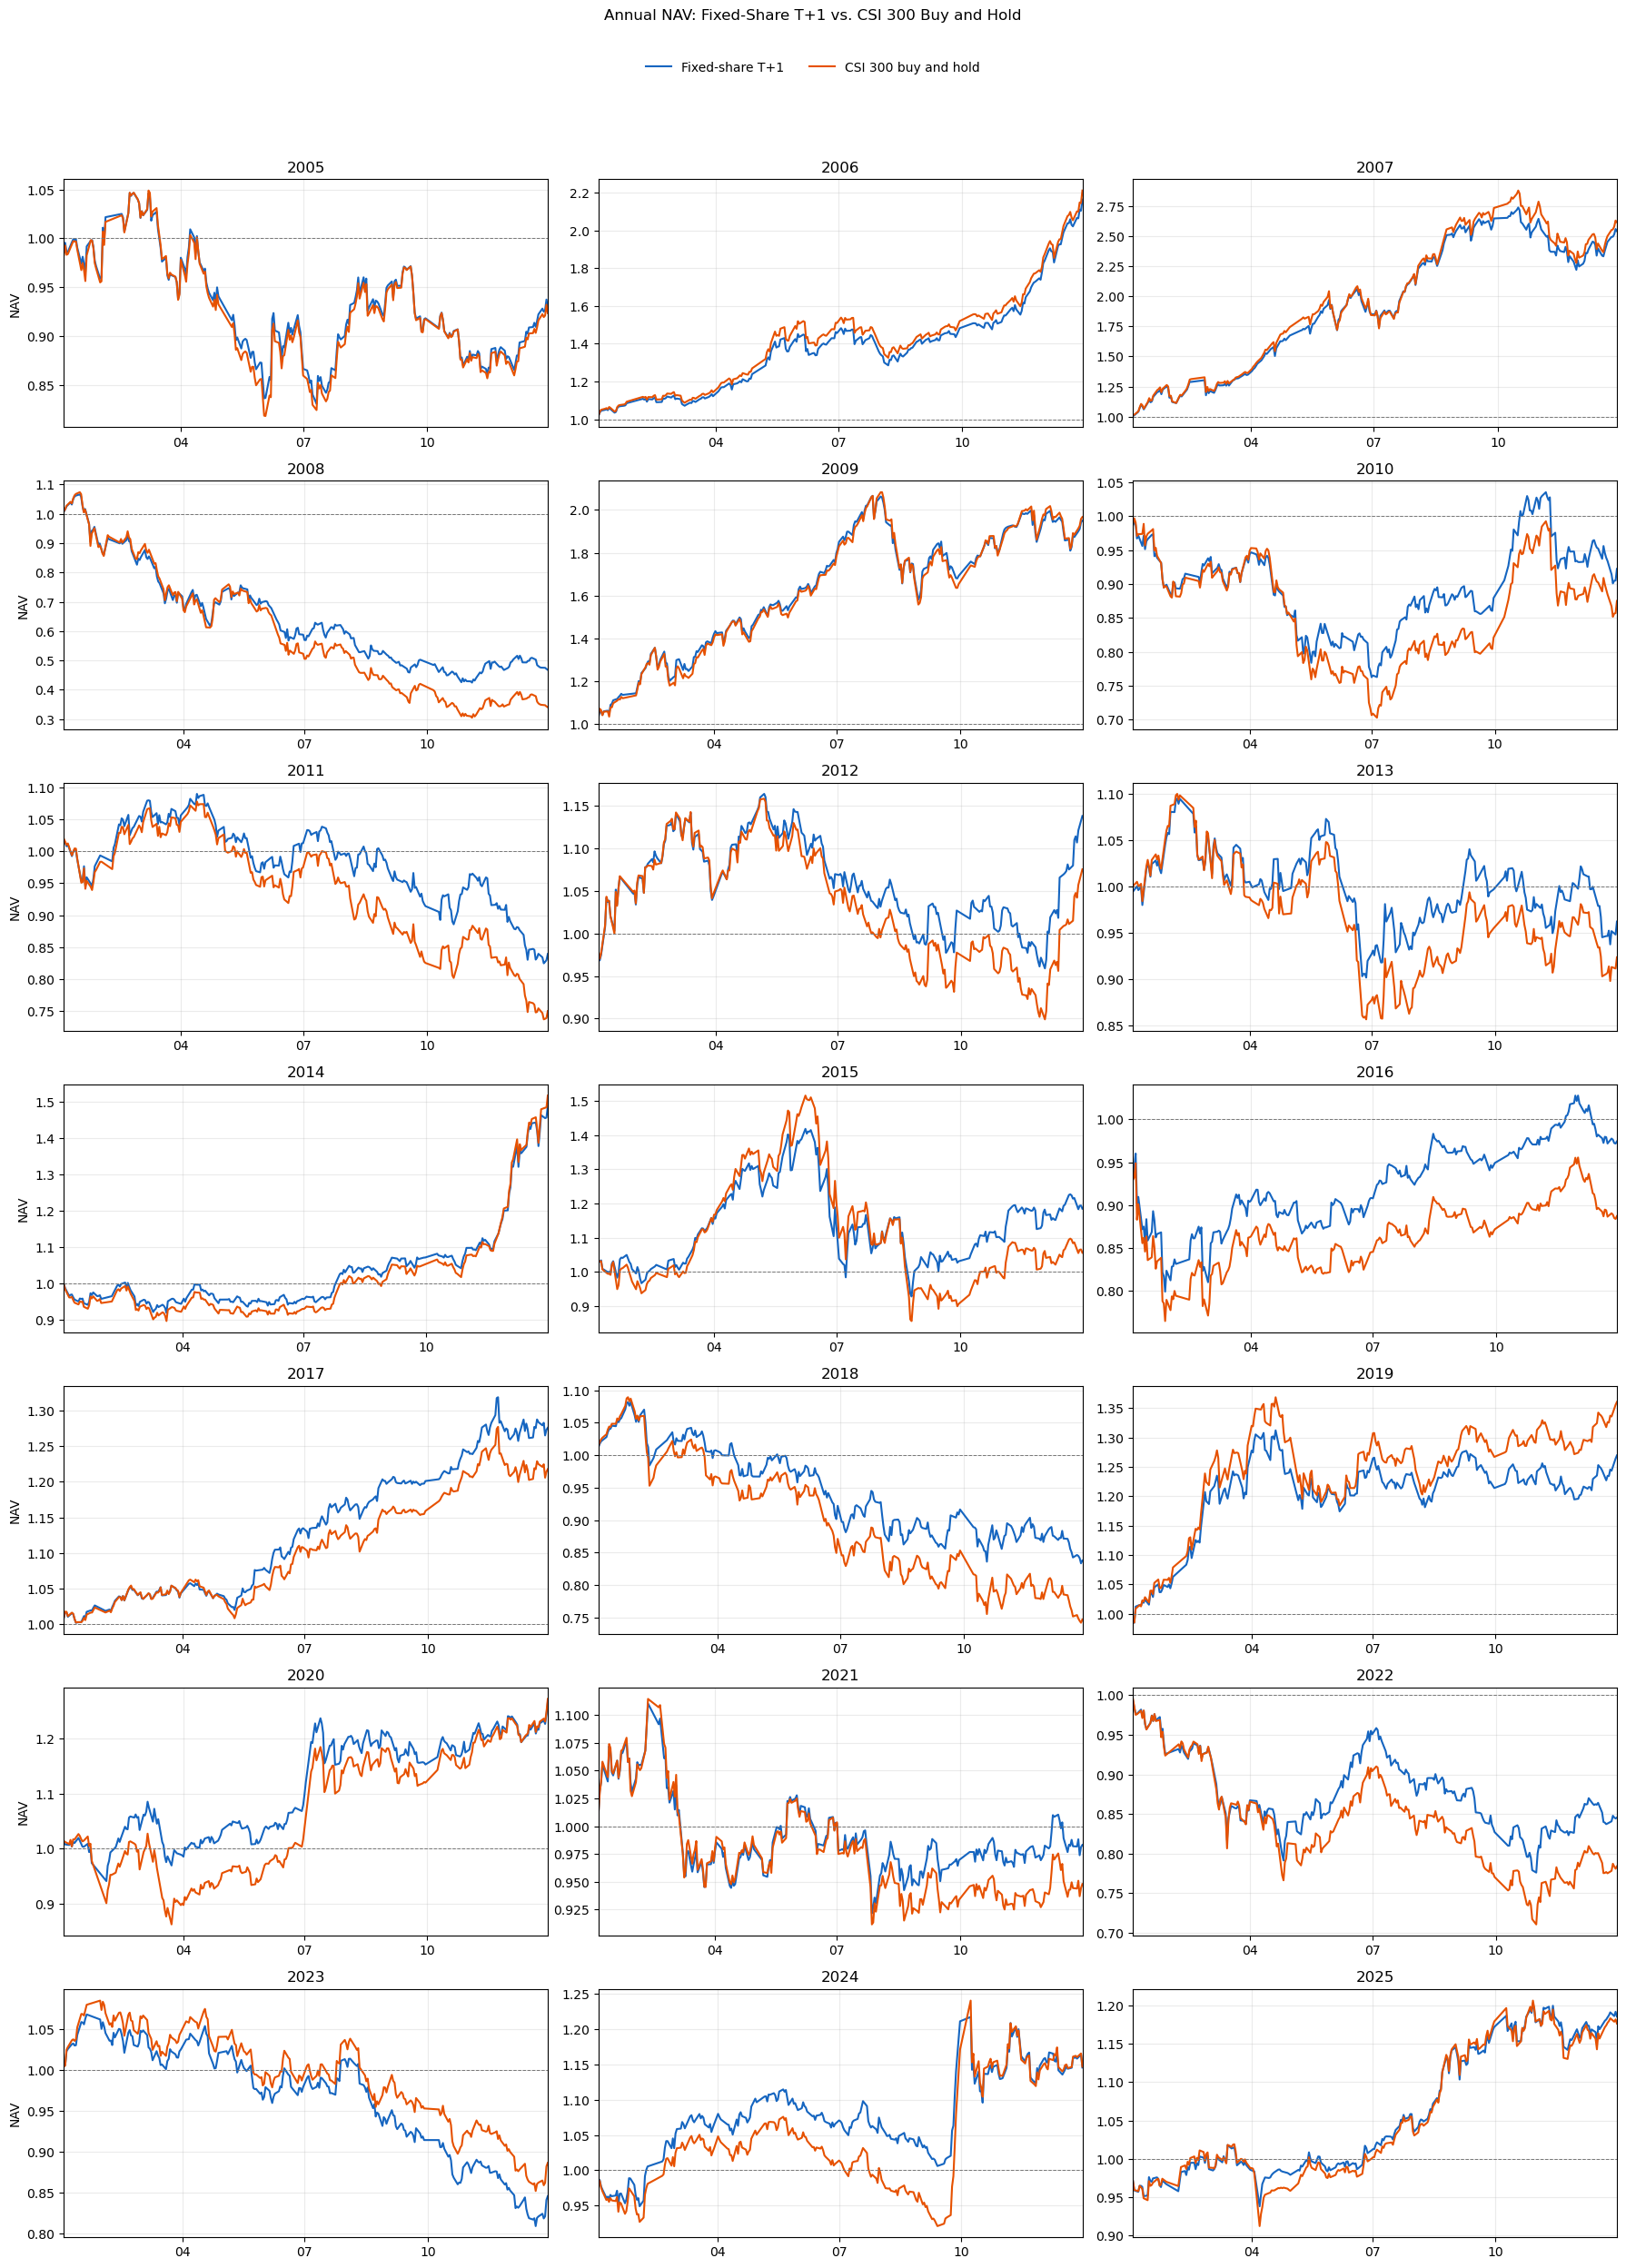

In [17]:
fig_annual, axes = plt.subplots(7, 3, figsize=(18, 25), sharex=False)
for ax, (year, yearly) in zip(axes.flat, backtest_df.groupby('year', sort=True)):
    ax.plot(yearly['date'], yearly['strategy_nav'], label='Fixed-share T+1',
            color='#1565C0', linewidth=1.5)
    ax.plot(yearly['date'], yearly['benchmark_nav'], label='CSI 300 buy and hold',
            color='#E65100', linewidth=1.5)
    ax.axhline(1.0, color='#777777', linewidth=0.7, linestyle='--')
    ax.set_title(str(year))
    ax.set_xlim(yearly['date'].iloc[0], yearly['date'].iloc[-1])
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m'))
    ax.grid(alpha=0.25)
for ax in axes[:, 0]:
    ax.set_ylabel('NAV')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig_annual.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.979),
                  ncol=2, frameon=False)
fig_annual.suptitle('Annual NAV: Fixed-Share T+1 vs. CSI 300 Buy and Hold', y=0.997)
fig_annual.tight_layout(rect=[0, 0, 1, 0.948])
plt.show()

## 三个跨年区间的累计净值

将每年已经计算的日收益率在 2005–2009、2010–2019、2020–2025 三个区间内分别复利串接，区间起点为 1.00。年度之间仍采用上面逐年重置的两批等份额交易规则；这里仅将年度回报连乘，未额外假设年末清仓。

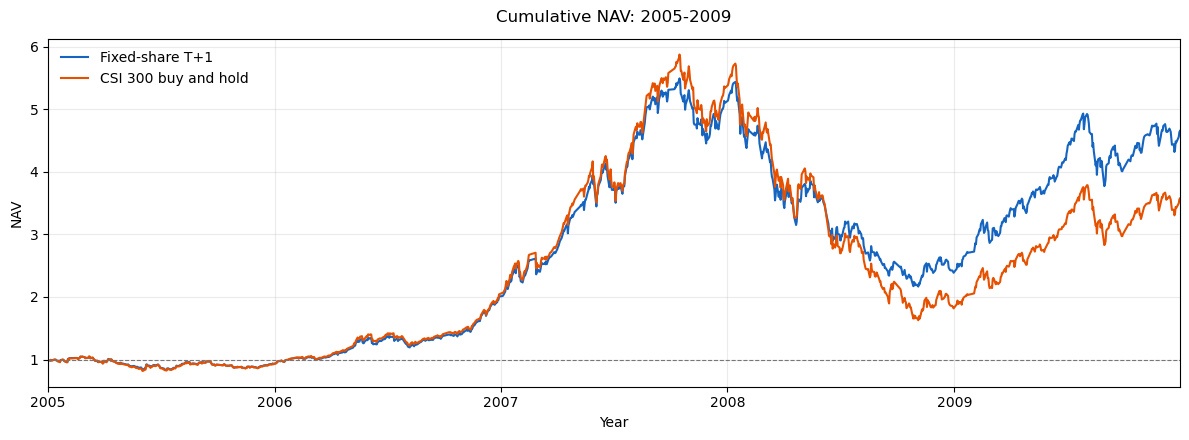

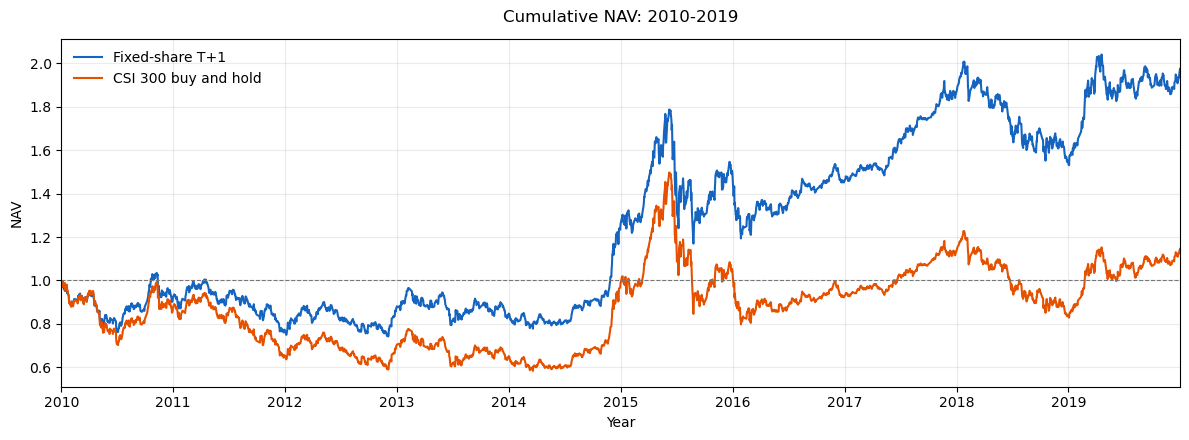

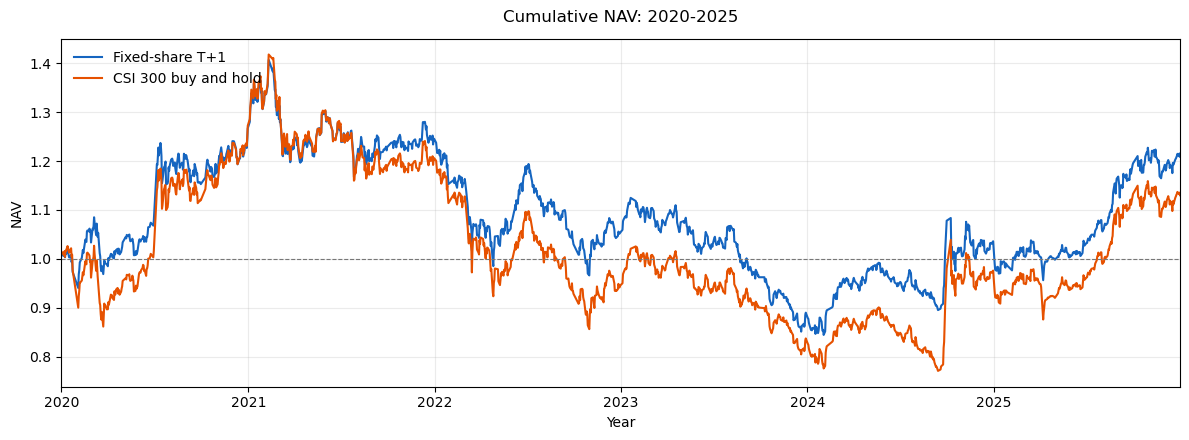

,strategy_cum_nav,benchmark_cum_nav
period,,
2005-2009,4.6553,3.5757
2010-2019,1.9744,1.1457
2020-2025,1.2091,1.1302


In [18]:
PERIOD_GROUPS = [(2005, 2009), (2010, 2019), (2020, 2025)]
multi_period_frames = []
period_figures = []

for start_year, end_year in PERIOD_GROUPS:
    period_name = f'{start_year}-{end_year}'
    period_data = backtest_df.loc[
        backtest_df['year'].between(start_year, end_year)
    ].sort_values('date').copy()
    period_data['period'] = period_name
    period_data['strategy_cum_nav'] = (1.0 + period_data['strategy_return']).cumprod()
    period_data['benchmark_cum_nav'] = (1.0 + period_data['benchmark_return']).cumprod()
    multi_period_frames.append(period_data[
        ['period', 'date', 'strategy_cum_nav', 'benchmark_cum_nav']
    ])

    period_fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(period_data['date'], period_data['strategy_cum_nav'],
            label='Fixed-share T+1', color='#1565C0', linewidth=1.5)
    ax.plot(period_data['date'], period_data['benchmark_cum_nav'],
            label='CSI 300 buy and hold', color='#E65100', linewidth=1.5)
    ax.axhline(1.0, color='#777777', linewidth=0.8, linestyle='--')
    ax.set_title(f'Cumulative NAV: {period_name}', pad=12)
    ax.set_ylabel('NAV')
    ax.set_xlabel('Year')
    ax.set_xlim(pd.Timestamp(f'{start_year}-01-01'), pd.Timestamp(f'{end_year}-12-31'))
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.grid(alpha=0.25)
    ax.legend(loc='upper left', frameon=False)
    period_fig.tight_layout()
    period_figures.append(period_fig)
    plt.show()

multi_period_nav = pd.concat(multi_period_frames, ignore_index=True)
multi_period_nav.groupby('period')[['strategy_cum_nav', 'benchmark_cum_nav']].last().round(4)